# 07 — Análisis de Separabilidad con variables fusionadas (supervisado)

**Pregunta:** ¿qué tan separables son los agarres y cuáles se confunden entre sí?

Este notebook usa las etiquetas, así que es un análisis **supervisado**. Sirve como referencia para el
clustering: si los agarres se separan mal incluso conociendo las etiquetas, el clustering sin etiquetas
no los va a separar mejor.

- **Datos**: `data/master/intact_boxcox_fused.csv` — salida del notebook de fusión (06): una fila por
  sujeto × agarre, con los 8 canales ya fusionados en una variable por feature. Solo se carga.
- **Features**: 8 variables fusionadas (`VAR_STD, Range, Energy, Peak_to_Peak, VAR, Max, MNF, SSC`).
- **Clases**: 7 agarres, sin reposo (`stimulus = 0`).
- **Validación**: LOSO con grupos `subject + origin_db` (los IDs de sujeto se repiten entre bases NinaPro,
  por eso el grupo es la combinación).

Para usar otro dataset solo se cambian `DATA_PATH` y `FEATURE_COLS`.

| Sección | Pregunta |
|---|---|
| 1. Carga | Dataset fusionado; solo se quita el reposo |
| 2. Fisher Discriminant Ratio | ¿Qué variables discriminan más? |
| 3. LDA multiclase en LOSO | ¿Se separan los agarres en un sujeto que el modelo no ha visto? |
| 4. Solapamiento por pares | ¿Qué pares de agarres se confunden? |
| 5. Silhouette por clase | ¿Cada agarre forma un grupo compacto? |
| 6. Proyección LDA | Visualización descriptiva |

In [1]:
import os
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (silhouette_score, silhouette_samples, accuracy_score,
                             balanced_accuracy_score, confusion_matrix)
from sklearn.model_selection import LeaveOneGroupOut

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

# ---------------- Parámetros ----------------
DATA_PATH = '../data/prueba/df_flat_wnd_mean.csv'
df = pd.read_csv(DATA_PATH)
FEATURE_COLS = list(df.columns[3:])
SAVE_DIR = '../figures/separabilidad_fused'

# Shrinkage de Ledoit-Wolf para LDA: estabiliza la covarianza (las variables de amplitud
# siguen muy correlacionadas entre sí aunque estén fusionadas).
#   'auto' (recomendado) | None (LDA clásica, para comparar)
SHRINKAGE = 'auto'
# --------------------------------------------

REST = 0
N_FEATURES = len(FEATURE_COLS)
STIM_COLORS = ['#E53935', '#8E24AA', '#1E88E5', '#00ACC1',
               '#43A047', '#FB8C00', '#F4511E', '#6D4C41', '#546E7A', '#C0CA33']

os.makedirs(SAVE_DIR, exist_ok=True)
print(f'Dataset: {DATA_PATH} ({N_FEATURES} variables)')
print(f'Figuras en: {SAVE_DIR}')
print(f'SHRINKAGE = {SHRINKAGE!r}')


def make_lda(shrinkage=SHRINKAGE, for_transform=False):
    # 'lsqr' para clasificar; 'eigen' cuando se necesita .transform() (proyección)
    solver = 'eigen' if for_transform else 'lsqr'
    if shrinkage is None and not for_transform:
        solver = 'svd'
    return LinearDiscriminantAnalysis(solver=solver, shrinkage=shrinkage)

Dataset: ../data/prueba/df_flat_wnd_mean.csv (200 variables)
Figuras en: ../figures/separabilidad_fused
SHRINKAGE = 'auto'


In [2]:
FEATURE_COLS 

['VAR_STD_w0',
 'VAR_STD_w1',
 'VAR_STD_w2',
 'VAR_STD_w3',
 'VAR_STD_w4',
 'VAR_STD_w5',
 'VAR_STD_w6',
 'VAR_STD_w7',
 'VAR_STD_w8',
 'VAR_STD_w9',
 'VAR_STD_w10',
 'VAR_STD_w11',
 'VAR_STD_w12',
 'VAR_STD_w13',
 'VAR_STD_w14',
 'VAR_STD_w15',
 'VAR_STD_w16',
 'VAR_STD_w17',
 'VAR_STD_w18',
 'VAR_STD_w19',
 'VAR_STD_w20',
 'VAR_STD_w21',
 'VAR_STD_w22',
 'VAR_STD_w23',
 'VAR_STD_w24',
 'Range_w0',
 'Range_w1',
 'Range_w2',
 'Range_w3',
 'Range_w4',
 'Range_w5',
 'Range_w6',
 'Range_w7',
 'Range_w8',
 'Range_w9',
 'Range_w10',
 'Range_w11',
 'Range_w12',
 'Range_w13',
 'Range_w14',
 'Range_w15',
 'Range_w16',
 'Range_w17',
 'Range_w18',
 'Range_w19',
 'Range_w20',
 'Range_w21',
 'Range_w22',
 'Range_w23',
 'Range_w24',
 'Energy_w0',
 'Energy_w1',
 'Energy_w2',
 'Energy_w3',
 'Energy_w4',
 'Energy_w5',
 'Energy_w6',
 'Energy_w7',
 'Energy_w8',
 'Energy_w9',
 'Energy_w10',
 'Energy_w11',
 'Energy_w12',
 'Energy_w13',
 'Energy_w14',
 'Energy_w15',
 'Energy_w16',
 'Energy_w17',
 'Energy_w

## 1. Carga

El dataset fusionado ya viene transformado (Box-Cox) y normalizado, así que aquí **solo se carga** y se quita
el reposo (si quedara alguno).

Los IDs de sujeto se repiten entre bases NinaPro, por eso el grupo LOSO es el ID compuesto
`subject + origin_db`.

In [3]:
missing = [c for c in ['stimulus', 'subject', 'origin_db'] + FEATURE_COLS if c not in df.columns]
if missing:
    raise KeyError(f'Faltan columnas en el CSV: {missing}')
print(f'Shape dataset original: {df.shape}')

# Eliminar muestras de reposo
df = df[df['stimulus'] != REST].copy().reset_index(drop=True)
df['group'] = df['subject'].astype(str) + '_' + df['origin_db'].astype(str)
print(f'Shape sin reposo:      {df.shape}')
print(f'Clases: {sorted(df["stimulus"].unique().tolist())}')
display(df['stimulus'].value_counts().sort_index().to_frame('n_muestras'))

counts = df.groupby('group').size()
print(f'Grupos LOSO (subject_origin_db): {counts.size}')
print(f'Muestras por grupo: {counts.min()} (mín) / {counts.max()} (máx)')

Shape dataset original: (609, 203)
Shape sin reposo:      (609, 204)
Clases: [22, 25, 27, 30, 31, 37, 40]


,n_muestras
stimulus,
22,87
25,87
27,87
30,87
31,87
37,87
40,87


Grupos LOSO (subject_origin_db): 87
Muestras por grupo: 7 (mín) / 7 (máx)


In [4]:
X = df[FEATURE_COLS].values.astype(float)
y = df['stimulus'].values
groups = df['group'].values

STIMULI = sorted(np.unique(y).tolist())
stim_color_map = dict(zip(STIMULI, STIM_COLORS))
CHANCE = 1 / len(STIMULI)
print(f'X: {X.shape} | clases: {STIMULI} | grupos LOSO: {len(np.unique(groups))} | azar = {CHANCE:.3f}')

X: (609, 200) | clases: [22, 25, 27, 30, 31, 37, 40] | grupos LOSO: 87 | azar = 0.143


## 2. Fisher Discriminant Ratio (FDR)

FDR por variable fusionada: variabilidad **entre agarres** / variabilidad **dentro de cada agarre**.
Valor mayor → mejor separación. Se calcula también el **FDR global** (agregado sobre todas las variables).

In [5]:
def fisher_ratio(X_col, y):
    # FDR univariado: SS_between / SS_within
    classes = np.unique(y)
    overall_mean = X_col.mean()
    ss_between = sum((y == c).sum() * (X_col[y == c].mean() - overall_mean) ** 2 for c in classes)
    ss_within = sum(((X_col[y == c] - X_col[y == c].mean()) ** 2).sum() for c in classes)
    return ss_between / ss_within if ss_within > 0 else np.nan


def fdr_global(X, y):
    # FDR agregado sobre todas las dimensiones
    classes = np.unique(y)
    overall_mean = X.mean(axis=0)
    ss_between = np.zeros(X.shape[1])
    ss_within = np.zeros(X.shape[1])
    for c in classes:
        X_c = X[y == c]
        ss_between += len(X_c) * (X_c.mean(axis=0) - overall_mean) ** 2
        ss_within += ((X_c - X_c.mean(axis=0)) ** 2).sum(axis=0)
    return ss_between.sum() / ss_within.sum() if ss_within.sum() > 0 else np.nan


fdr_values = np.array([fisher_ratio(X[:, i], y) for i in range(X.shape[1])])
fdr_global_value = fdr_global(X, y)

fdr_df = (pd.DataFrame({'Variable': FEATURE_COLS, 'FDR': fdr_values})
          .sort_values('FDR', ascending=False).reset_index(drop=True))
fdr_df.index = fdr_df.index + 1

print(f'FDR global ({N_FEATURES} variables): {fdr_global_value:.4f}')
display(fdr_df.style.format({'FDR': '{:.4f}'}))

FDR global (200 variables): 0.3811


,Variable,FDR
1,Max_w22,1.2010
2,Max_w21,1.1867
3,Energy_w21,1.1791
4,Energy_w22,1.1673
5,Max_w23,1.1444
6,Peak_to_Peak_w21,1.1387
7,Peak_to_Peak_w22,1.1323
8,Max_w20,1.1133
9,Energy_w20,1.1118
10,VAR_STD_w21,1.0996


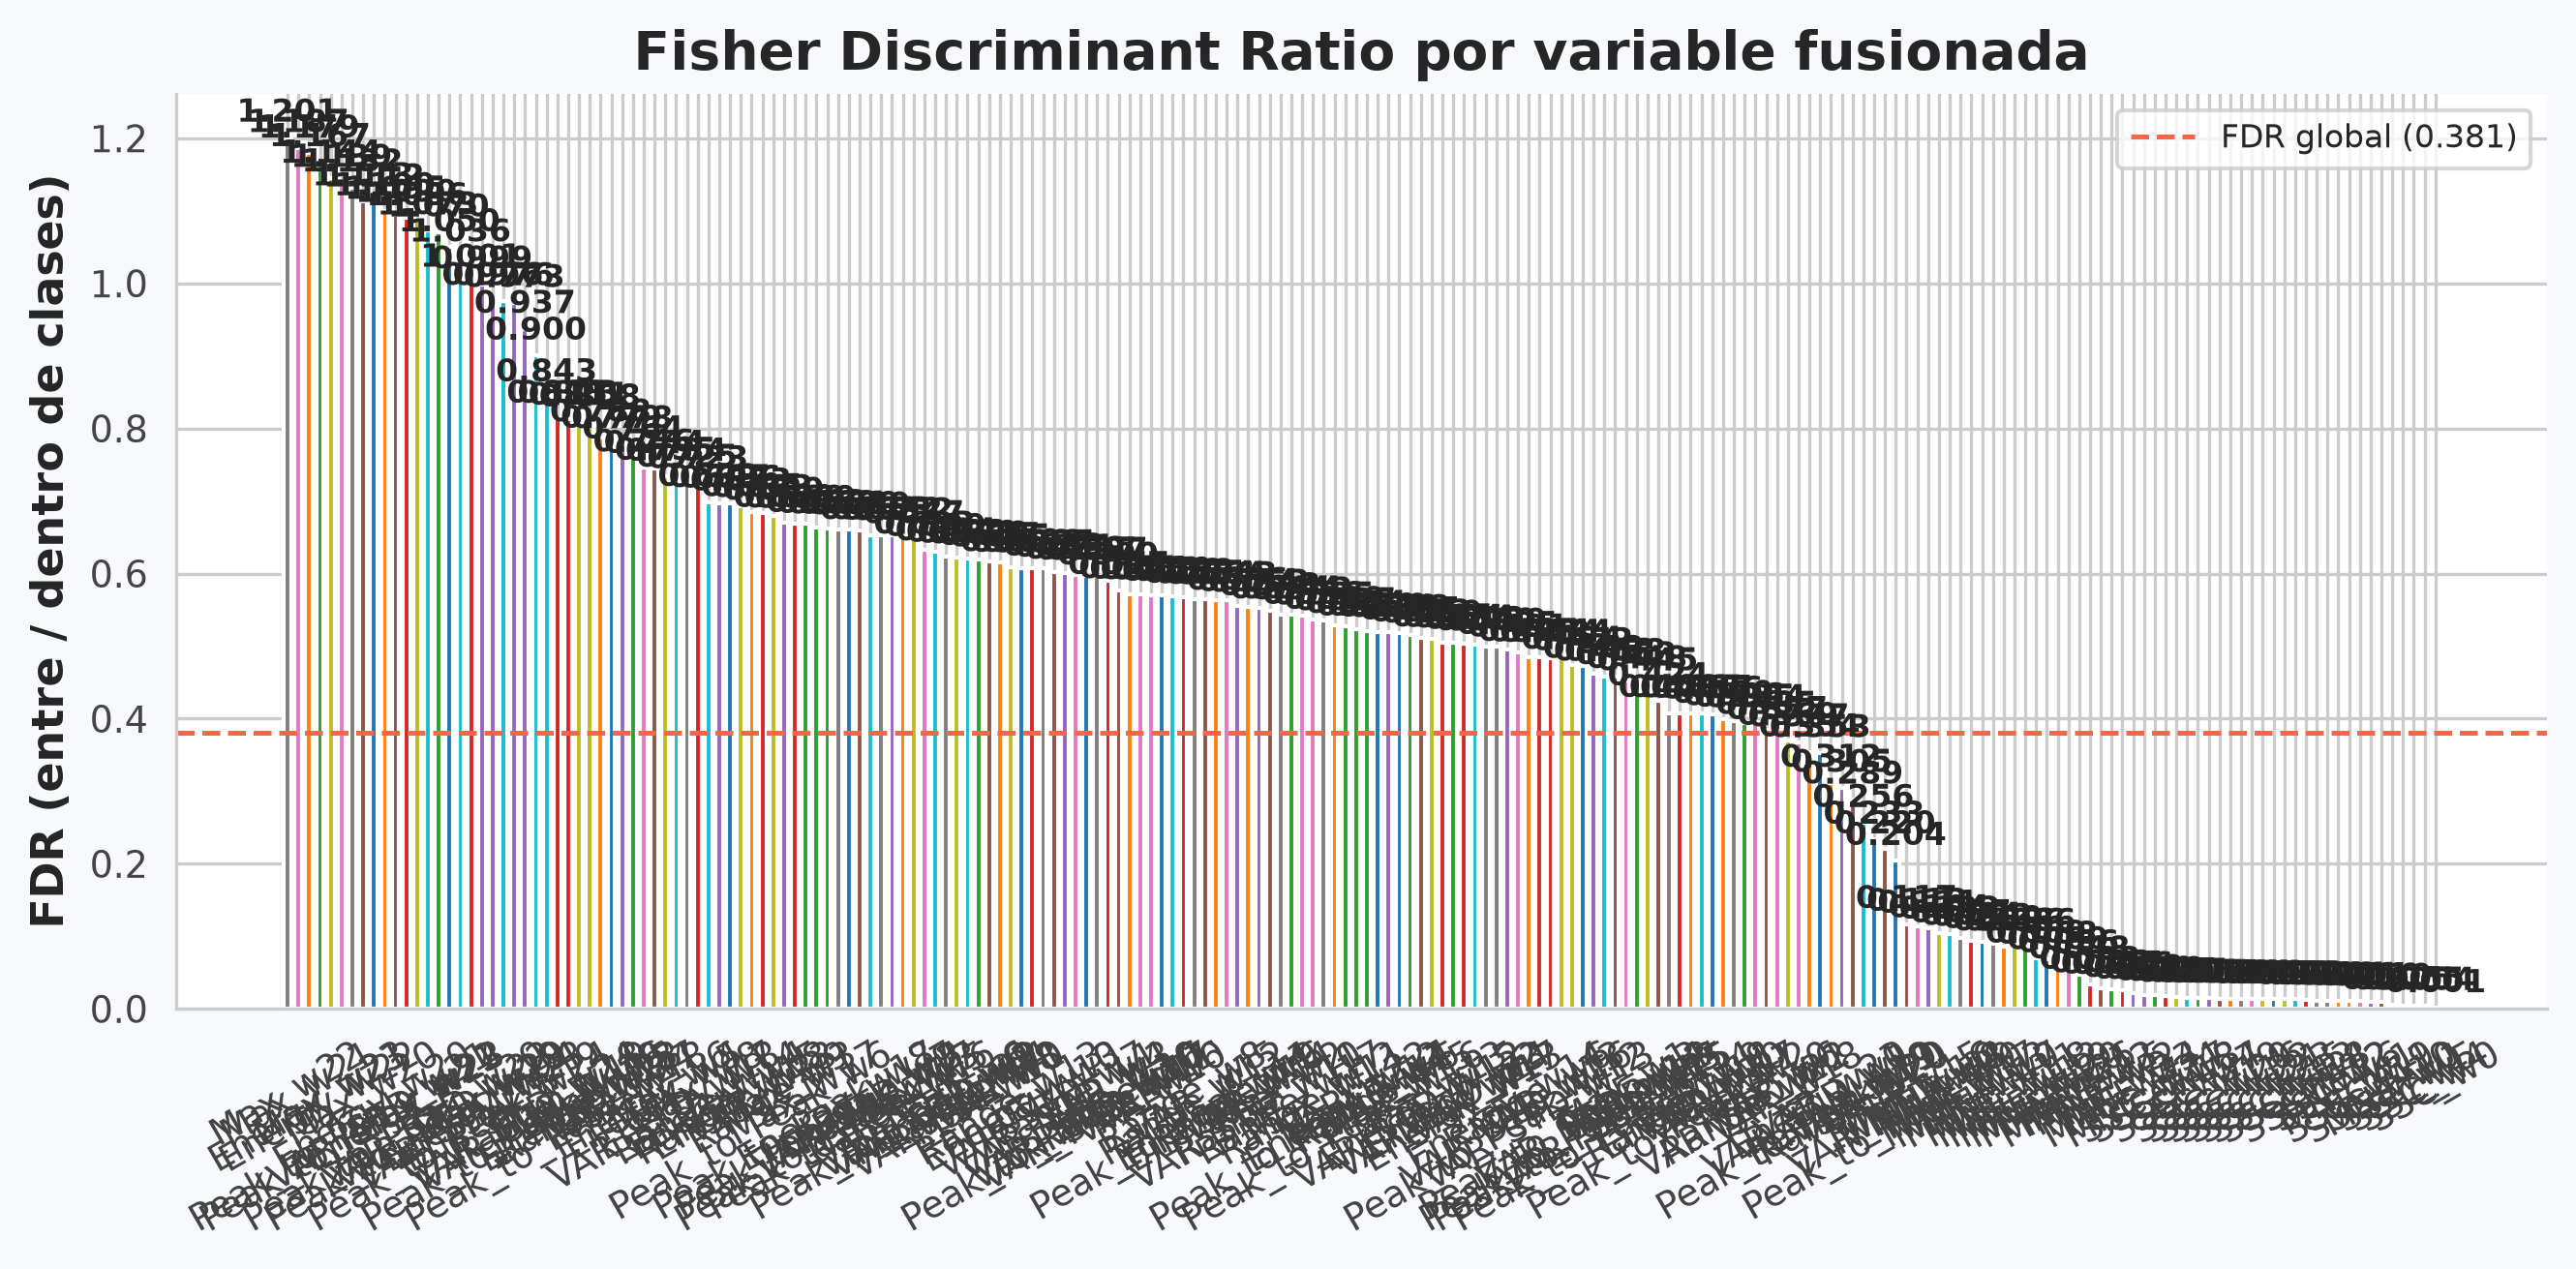

In [6]:
feat_palette = dict(zip(FEATURE_COLS, sns.color_palette('tab10', N_FEATURES)))

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=300)
fig.patch.set_facecolor('#F7F9FC')
ax.set_facecolor('#FFFFFF')

bars = ax.bar(fdr_df['Variable'], fdr_df['FDR'],
              color=[feat_palette[f] for f in fdr_df['Variable']], edgecolor='white', width=0.7)
ax.bar_label(bars, fmt='%.3f', fontsize=8, fontweight='bold', padding=2)
ax.axhline(fdr_global_value, color='tomato', linestyle='--', linewidth=1.2,
           label=f'FDR global ({fdr_global_value:.3f})')

ax.set_ylabel('FDR (entre / dentro de clases)', fontweight='bold')
ax.set_title('Fisher Discriminant Ratio por variable fusionada', fontweight='bold')
ax.tick_params(axis='x', rotation=30)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#CCCCCC')
ax.tick_params(colors='#444444', labelsize=9)
ax.legend(frameon=True, fontsize=8)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/fdr_features.pdf', dpi=300, bbox_inches='tight')
plt.show()

## 3. LDA multiclase con LOSO

En cada pliegue se entrena una LDA con 86 sujetos y se predicen los 7 agarres del sujeto excluido.
Así se mide si los agarres se separan **en una persona que el modelo no ha visto**.

- `shrinkage='auto'` (Ledoit-Wolf): las variables de amplitud siguen muy correlacionadas entre sí, y la regularización estabiliza la covarianza.
- Se reporta accuracy por sujeto (media ± desviación) frente al nivel de azar (1 / número de agarres).
- La matriz de confusión acumulada es la medida principal de **solapamiento entre agarres**.

La LDA aquí no es el clasificador final del proyecto: es un medidor lineal e interpretable de separabilidad.

In [7]:
logo = LeaveOneGroupOut()
y_pred = np.empty_like(y)
per_group = []

for train_idx, test_idx in logo.split(X, y, groups):
    clf = make_lda()
    clf.fit(X[train_idx], y[train_idx])
    pred = clf.predict(X[test_idx])
    y_pred[test_idx] = pred
    per_group.append({'grupo': groups[test_idx][0],
                      'accuracy': accuracy_score(y[test_idx], pred)})

per_group_df = pd.DataFrame(per_group)
acc_global = accuracy_score(y, y_pred)
bacc_global = balanced_accuracy_score(y, y_pred)

print(f'LOSO ({len(per_group_df)} pliegues, {N_FEATURES} variables) — LDA shrinkage={SHRINKAGE!r}')
print(f'Accuracy global:           {acc_global:.3f}')
print(f'Balanced accuracy:         {bacc_global:.3f}')
print(f'Accuracy por sujeto:       {per_group_df["accuracy"].mean():.3f} ± '
      f'{per_group_df["accuracy"].std():.3f}')
print(f'Nivel de azar:             {CHANCE:.3f}')
print(f'Sujetos por debajo del azar: {(per_group_df["accuracy"] <= CHANCE).sum()} '
      f'de {len(per_group_df)}')

cm = confusion_matrix(y, y_pred, labels=STIMULI, normalize='true')
cm_df = pd.DataFrame(cm, index=STIMULI, columns=STIMULI)
cm_df.index.name = 'Real'
cm_df.columns.name = 'Predicho'

recall_df = pd.Series(np.diag(cm), index=STIMULI, name='Recall').to_frame()
recall_df.index.name = 'Estímulo'
display(recall_df.T.style.format('{:.3f}'))

LOSO (87 pliegues, 200 variables) — LDA shrinkage='auto'
Accuracy global:           0.724
Balanced accuracy:         0.724
Accuracy por sujeto:       0.724 ± 0.179
Nivel de azar:             0.143
Sujetos por debajo del azar: 0 de 87


Estímulo,22,25,27,30,31,37,40
Recall,0.644,0.644,0.644,0.678,0.747,0.782,0.931


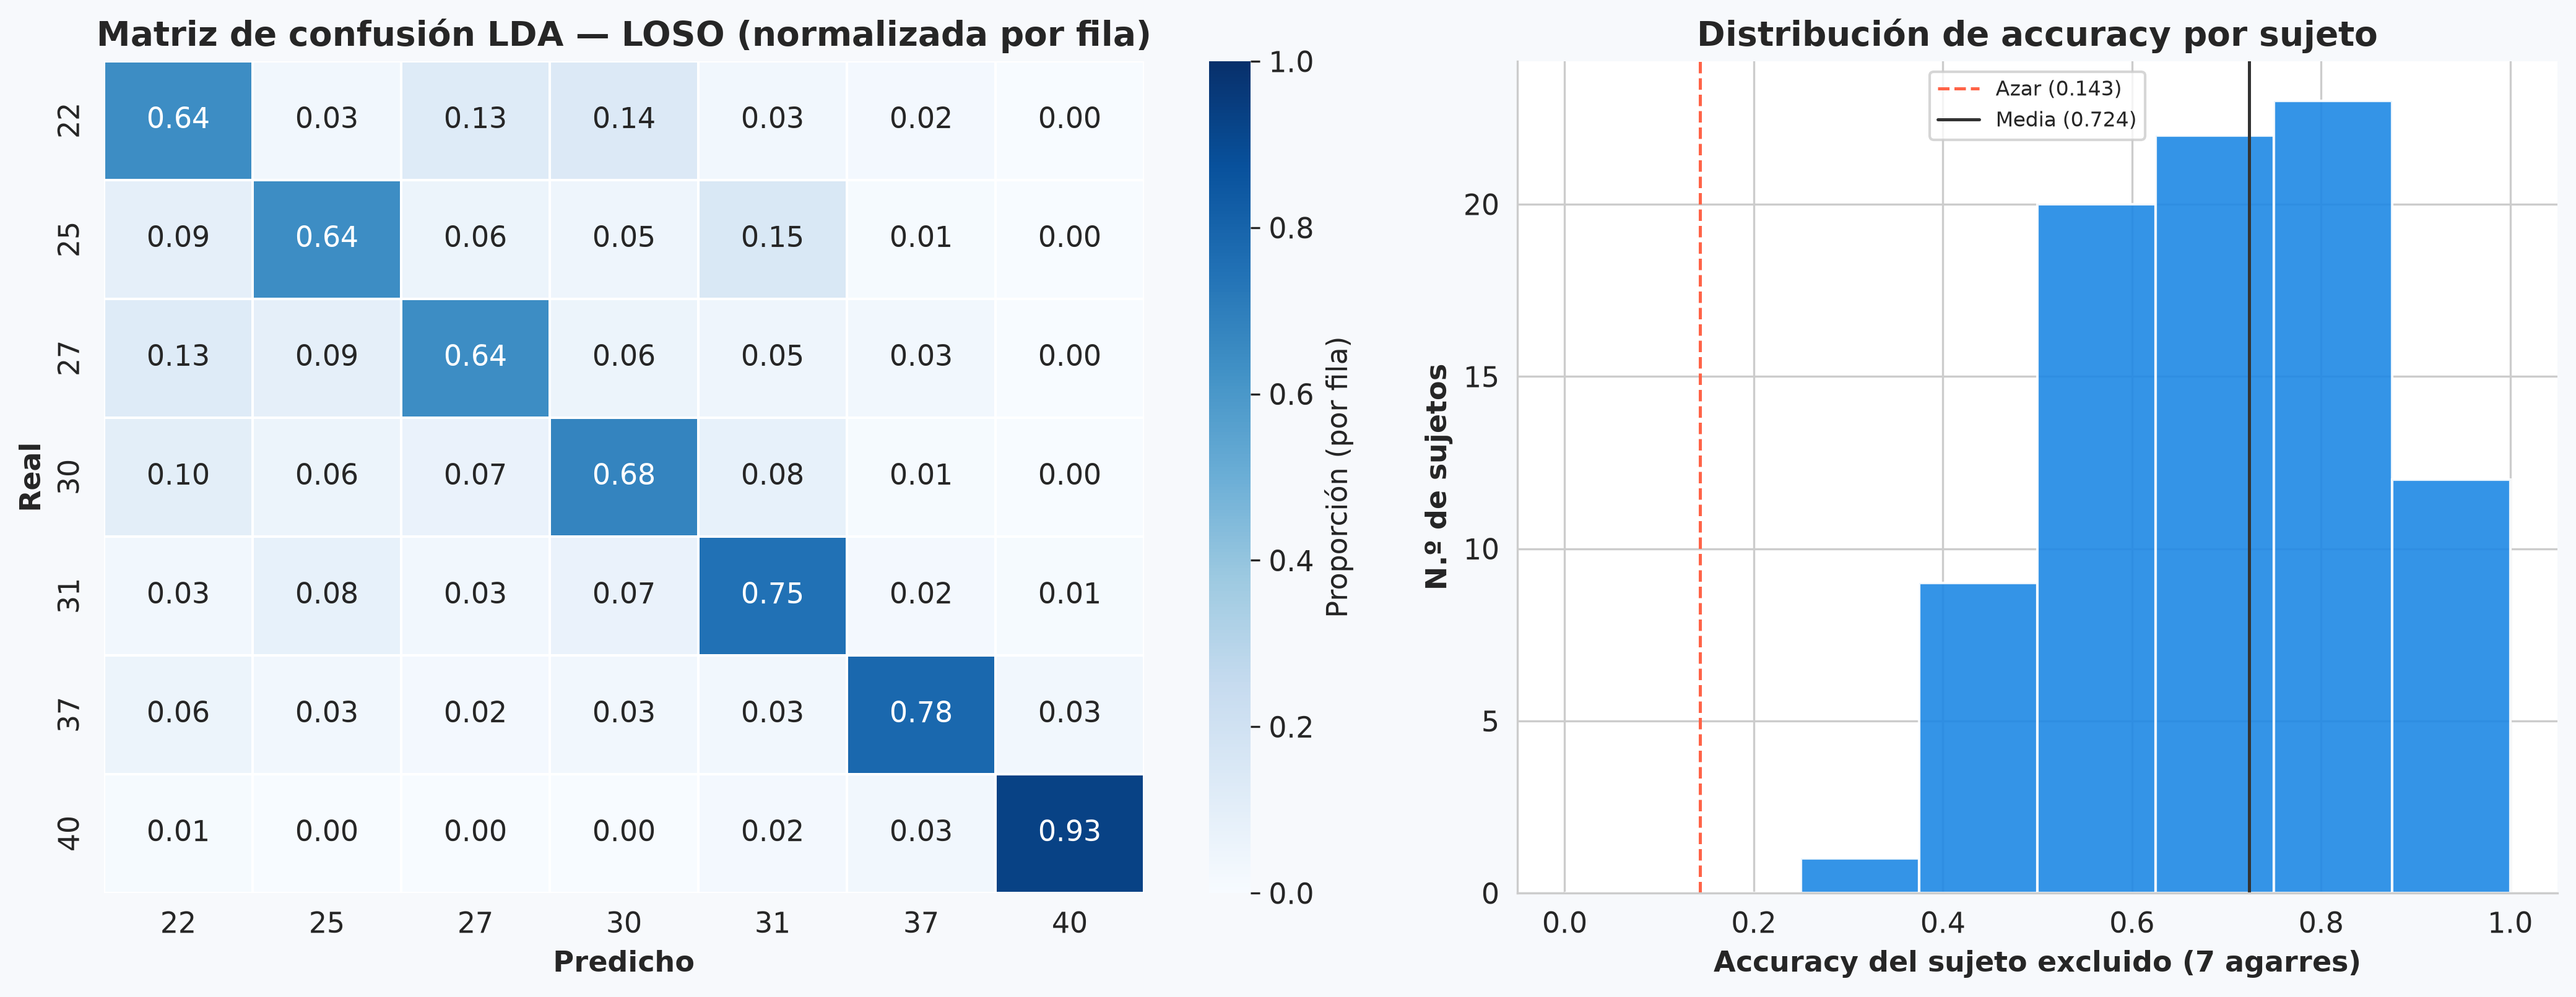

Top-5 pares más confundidos en la LDA multiclase:


,agarre_a,agarre_b,confusion
1,22,27,0.126
2,22,30,0.121
3,25,31,0.115
4,25,27,0.075
5,30,31,0.075


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300,
                         gridspec_kw={'width_ratios': [1.25, 1]})
fig.patch.set_facecolor('#F7F9FC')

ax = axes[0]
sns.heatmap(cm_df, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
            linewidths=0.5, linecolor='#FFFFFF', cbar_kws={'label': 'Proporción (por fila)'}, ax=ax)
ax.set_title('Matriz de confusión LDA — LOSO (normalizada por fila)', fontweight='bold')
ax.set_xlabel('Predicho', fontweight='bold')
ax.set_ylabel('Real', fontweight='bold')

ax = axes[1]
ax.set_facecolor('#FFFFFF')
ax.hist(per_group_df['accuracy'], bins=np.linspace(0, 1, 9), color='#1E88E5',
        edgecolor='white', alpha=0.9)
ax.axvline(CHANCE, color='tomato', linestyle='--', linewidth=1.2, label=f'Azar ({CHANCE:.3f})')
ax.axvline(per_group_df['accuracy'].mean(), color='#333333', linestyle='-', linewidth=1.2,
           label=f'Media ({per_group_df["accuracy"].mean():.3f})')
ax.set_xlabel(f'Accuracy del sujeto excluido ({len(STIMULI)} agarres)', fontweight='bold')
ax.set_ylabel('N.º de sujetos', fontweight='bold')
ax.set_title('Distribución de accuracy por sujeto', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=True, fontsize=8)

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/lda_loso_confusion.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Confusiones más frecuentes (fuera de la diagonal, simetrizadas)
conf_pairs = [{'agarre_a': STIMULI[a], 'agarre_b': STIMULI[b],
               'confusion': (cm[a, b] + cm[b, a]) / 2}
              for a, b in itertools.combinations(range(len(STIMULI)), 2)]
conf_pairs_df = (pd.DataFrame(conf_pairs).sort_values('confusion', ascending=False)
                 .reset_index(drop=True))
conf_pairs_df.index = conf_pairs_df.index + 1
print('Top-5 pares más confundidos en la LDA multiclase:')
display(conf_pairs_df.head(5).style.format({'confusion': '{:.3f}'}))

## 4. Matriz de solapamiento entre agarres (error LDA por pares)

Para cada par `(i, j)` se ajusta una LDA solo con esas dos clases y se mide el error con **LOSO**
(un pliegue por sujeto, 2 muestras por pliegue).

A diferencia de la matriz de confusión multiclase, esta mide cada par **aislado**, sin la competencia
de los demás agarres. La diagonal es 0. Valores altos ⇒ mayor solapamiento.

In [9]:
def lda_pair_error(i, j, X, y, groups):
    # Tasa de error LOSO de una LDA entrenada solo con los agarres i y j
    mask = np.isin(y, [i, j])
    Xp, yp, gp = X[mask], y[mask], groups[mask]
    errors, total = 0, 0
    for train_idx, test_idx in LeaveOneGroupOut().split(Xp, yp, gp):
        clf = make_lda()
        clf.fit(Xp[train_idx], yp[train_idx])
        errors += int((clf.predict(Xp[test_idx]) != yp[test_idx]).sum())
        total += len(test_idx)
    return errors / total if total > 0 else np.nan

n = len(STIMULI)
overlap = np.zeros((n, n))
for a, b in itertools.combinations(range(n), 2):
    overlap[a, b] = overlap[b, a] = lda_pair_error(STIMULI[a], STIMULI[b], X, y, groups)

overlap_df = pd.DataFrame(overlap, index=STIMULI, columns=STIMULI)
overlap_df.index.name = 'Estímulo'
print(f'Error medio de los {n * (n - 1) // 2} pares: {overlap[np.triu_indices(n, 1)].mean():.3f} '
     f'(azar en un par = 0.5)')

Error medio de los 21 pares: 0.090 (azar en un par = 0.5)


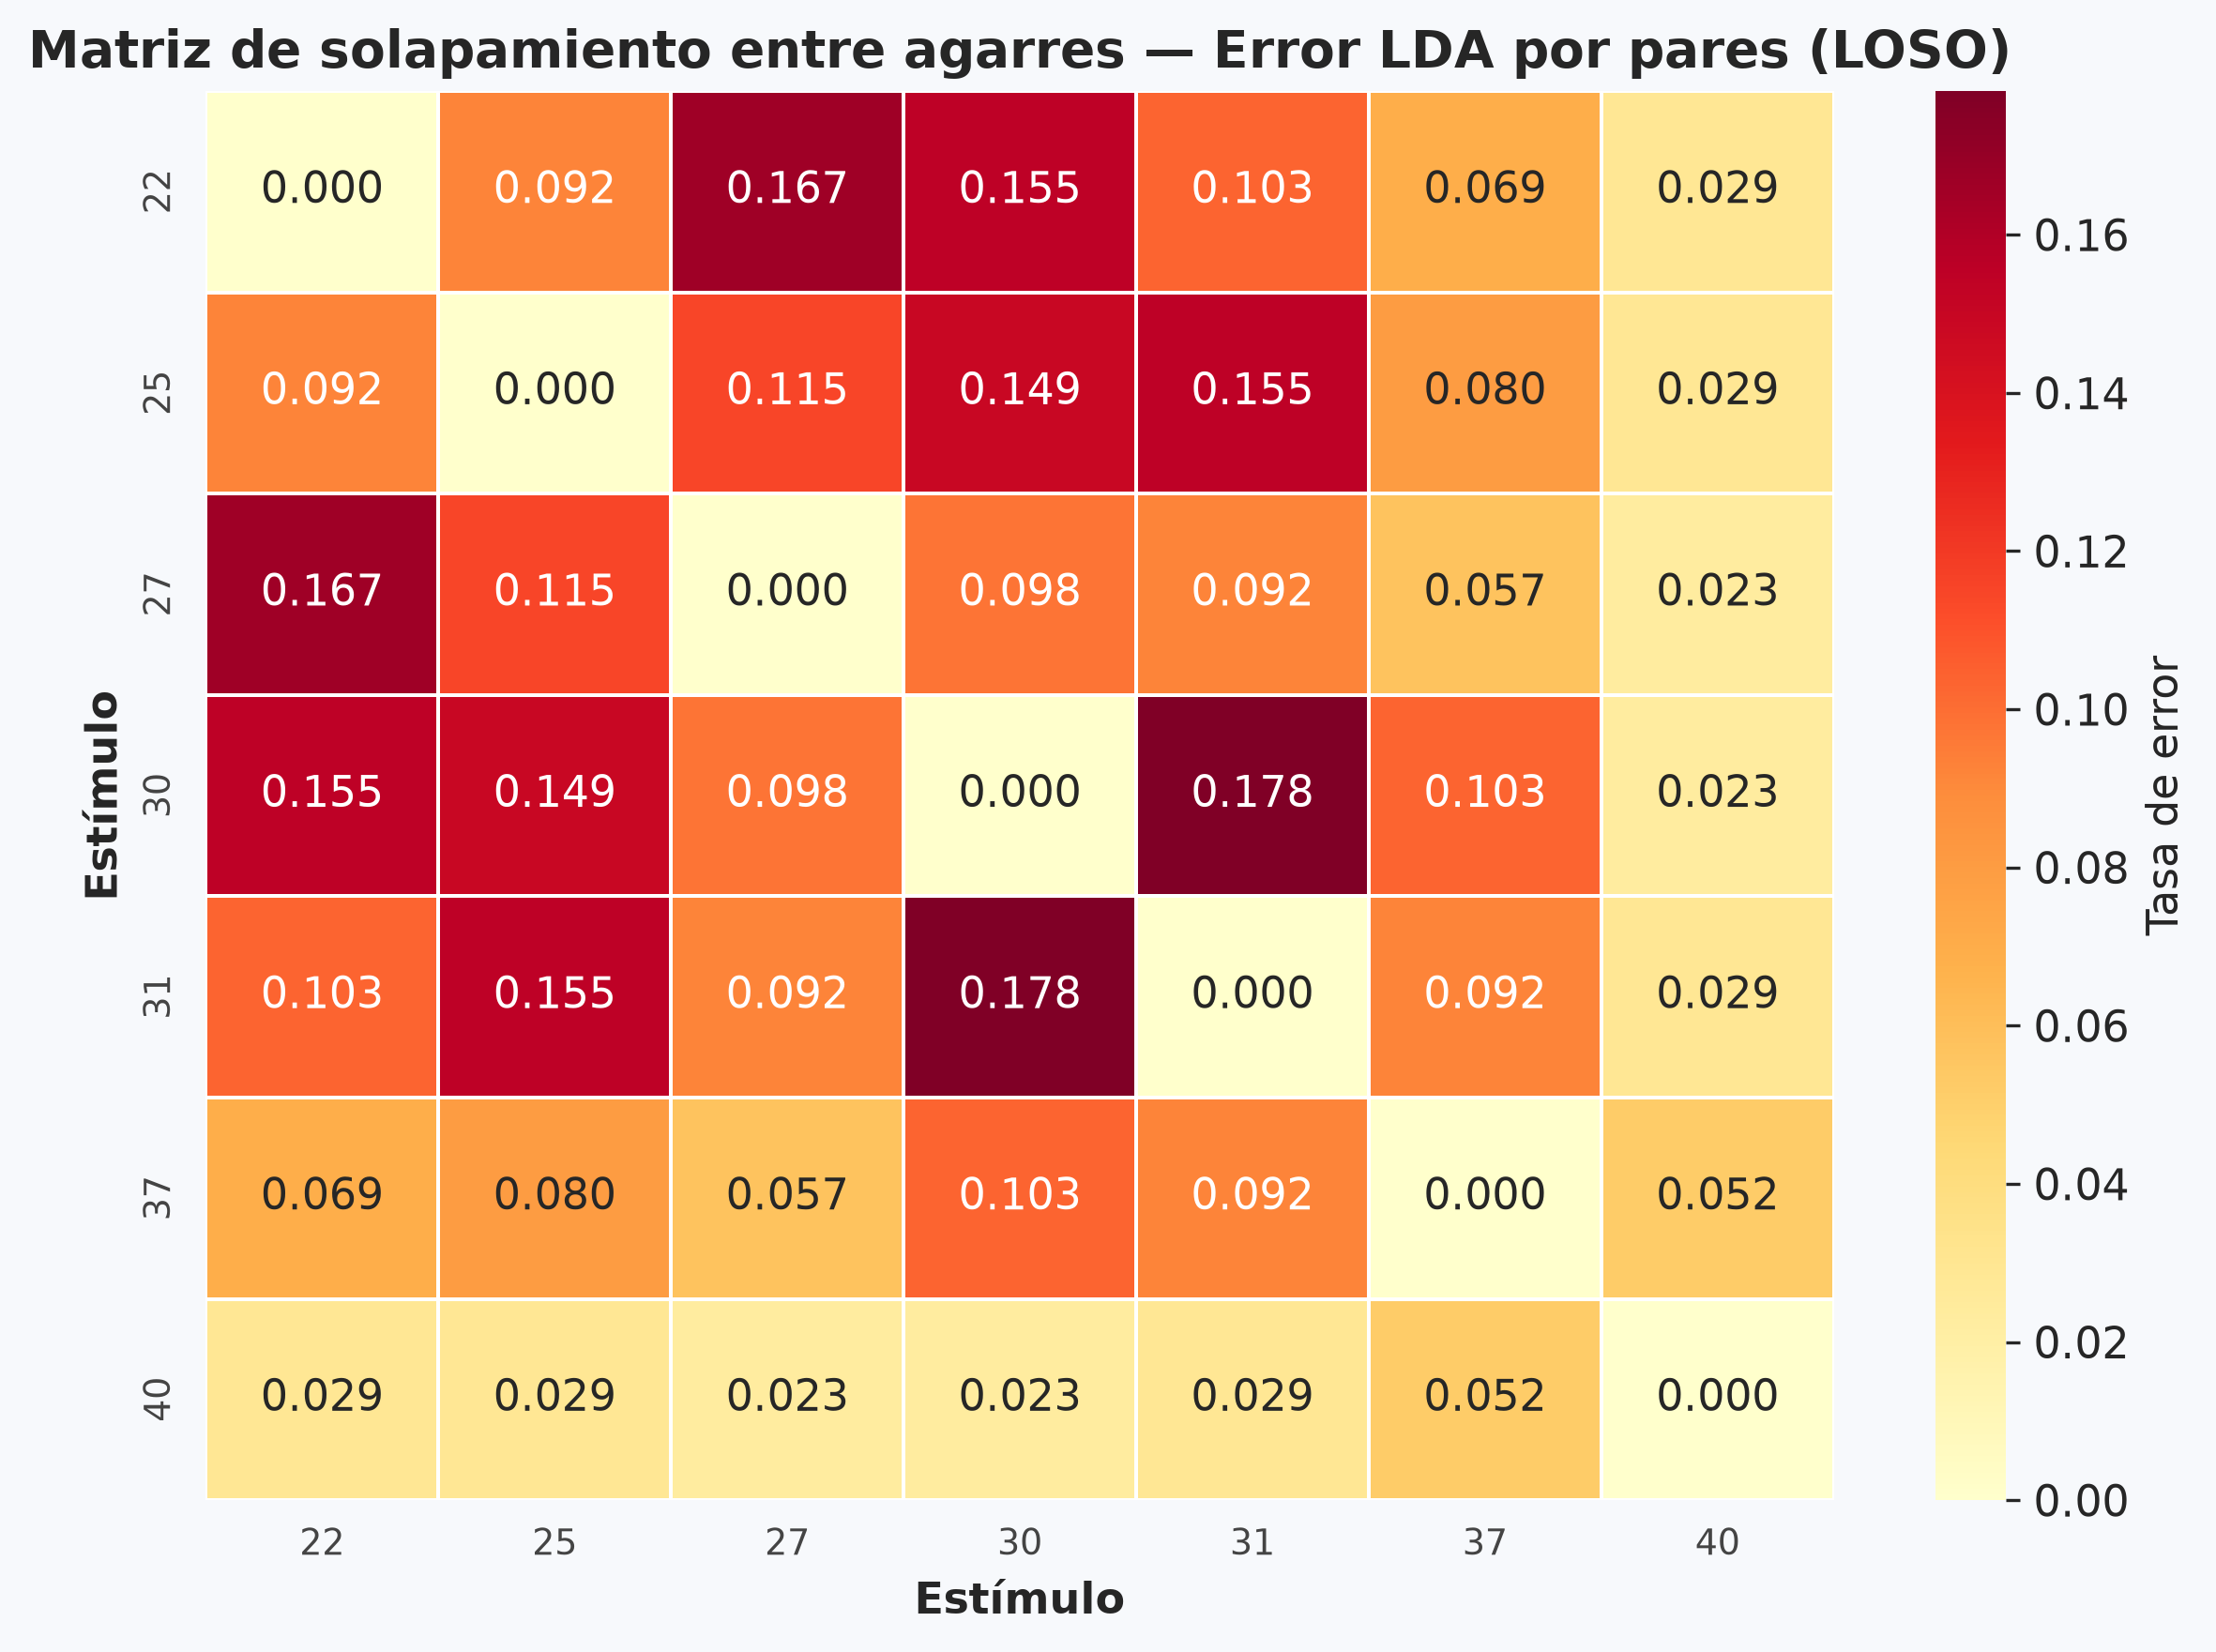

Top-5 pares más solapados (mayor error LOSO):


,agarre_a,agarre_b,error
1,30,31,0.178
2,22,27,0.167
3,22,30,0.155
4,25,31,0.155
5,25,30,0.149


Top-3 pares menos solapados:


,agarre_a,agarre_b,error
19,31,40,0.029
20,27,40,0.023
21,30,40,0.023


In [10]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
fig.patch.set_facecolor('#F7F9FC')
ax.set_facecolor('#FFFFFF')

sns.heatmap(overlap_df, annot=True, fmt='.3f', cmap='YlOrRd', vmin=0,
            linewidths=0.5, linecolor='#FFFFFF', cbar_kws={'label': 'Tasa de error'}, ax=ax)

ax.set_title('Matriz de solapamiento entre agarres — Error LDA por pares (LOSO)',
             fontweight='bold')
ax.set_xlabel('Estímulo', fontweight='bold')
ax.set_ylabel('Estímulo', fontweight='bold')
ax.tick_params(colors='#444444', labelsize=9)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/overlap_matrix.pdf', dpi=300, bbox_inches='tight')
plt.show()

pairs = [{'agarre_a': STIMULI[a], 'agarre_b': STIMULI[b], 'error': overlap[a, b]}
         for a, b in itertools.combinations(range(n), 2)]
pairs_df = pd.DataFrame(pairs).sort_values('error', ascending=False).reset_index(drop=True)
pairs_df.index = pairs_df.index + 1
print('Top-5 pares más solapados (mayor error LOSO):')
display(pairs_df.head(5).style.format({'error': '{:.3f}'}))
print('Top-3 pares menos solapados:')
display(pairs_df.tail(3).style.format({'error': '{:.3f}'}))

## 5. Silhouette por clase

`silhouette_samples` con distancia euclídea sobre las variables fusionadas, agrupado por agarre.
Cerca de 1 → la muestra está más cerca de su agarre que de los demás; cerca de 0 o negativo → solapamiento.

**Cuidado al interpretarlo:** 6 de las 8 variables son de amplitud (VAR, Energy, Range, Peak_to_Peak, Max,
VAR_STD) y están muy correlacionadas, así que en la distancia euclídea la amplitud pesa más que MNF o SSC.
La LDA (sección 3) encuentra direcciones discriminativas que la distancia euclídea no ve; por eso los dos
resultados pueden discrepar.

In [11]:
sil_samples = silhouette_samples(X, y)
sil_global = silhouette_score(X, y)
df['silhouette'] = sil_samples

sil_class = (df.groupby('stimulus')['silhouette']
             .agg(media='mean', desv='std', n='count').round(4))
sil_class.index.name = 'Estímulo'
print(f'Silhouette global: {sil_global:.4f}')
display(sil_class)

Silhouette global: 0.0014


,media,desv,n
Estímulo,,,
22,0.0163,0.0837,87
25,-0.0910,0.0939,87
27,0.0004,0.1182,87
30,-0.0191,0.0919,87
31,0.1101,0.1612,87
37,-0.0131,0.0959,87
40,0.0060,0.1040,87


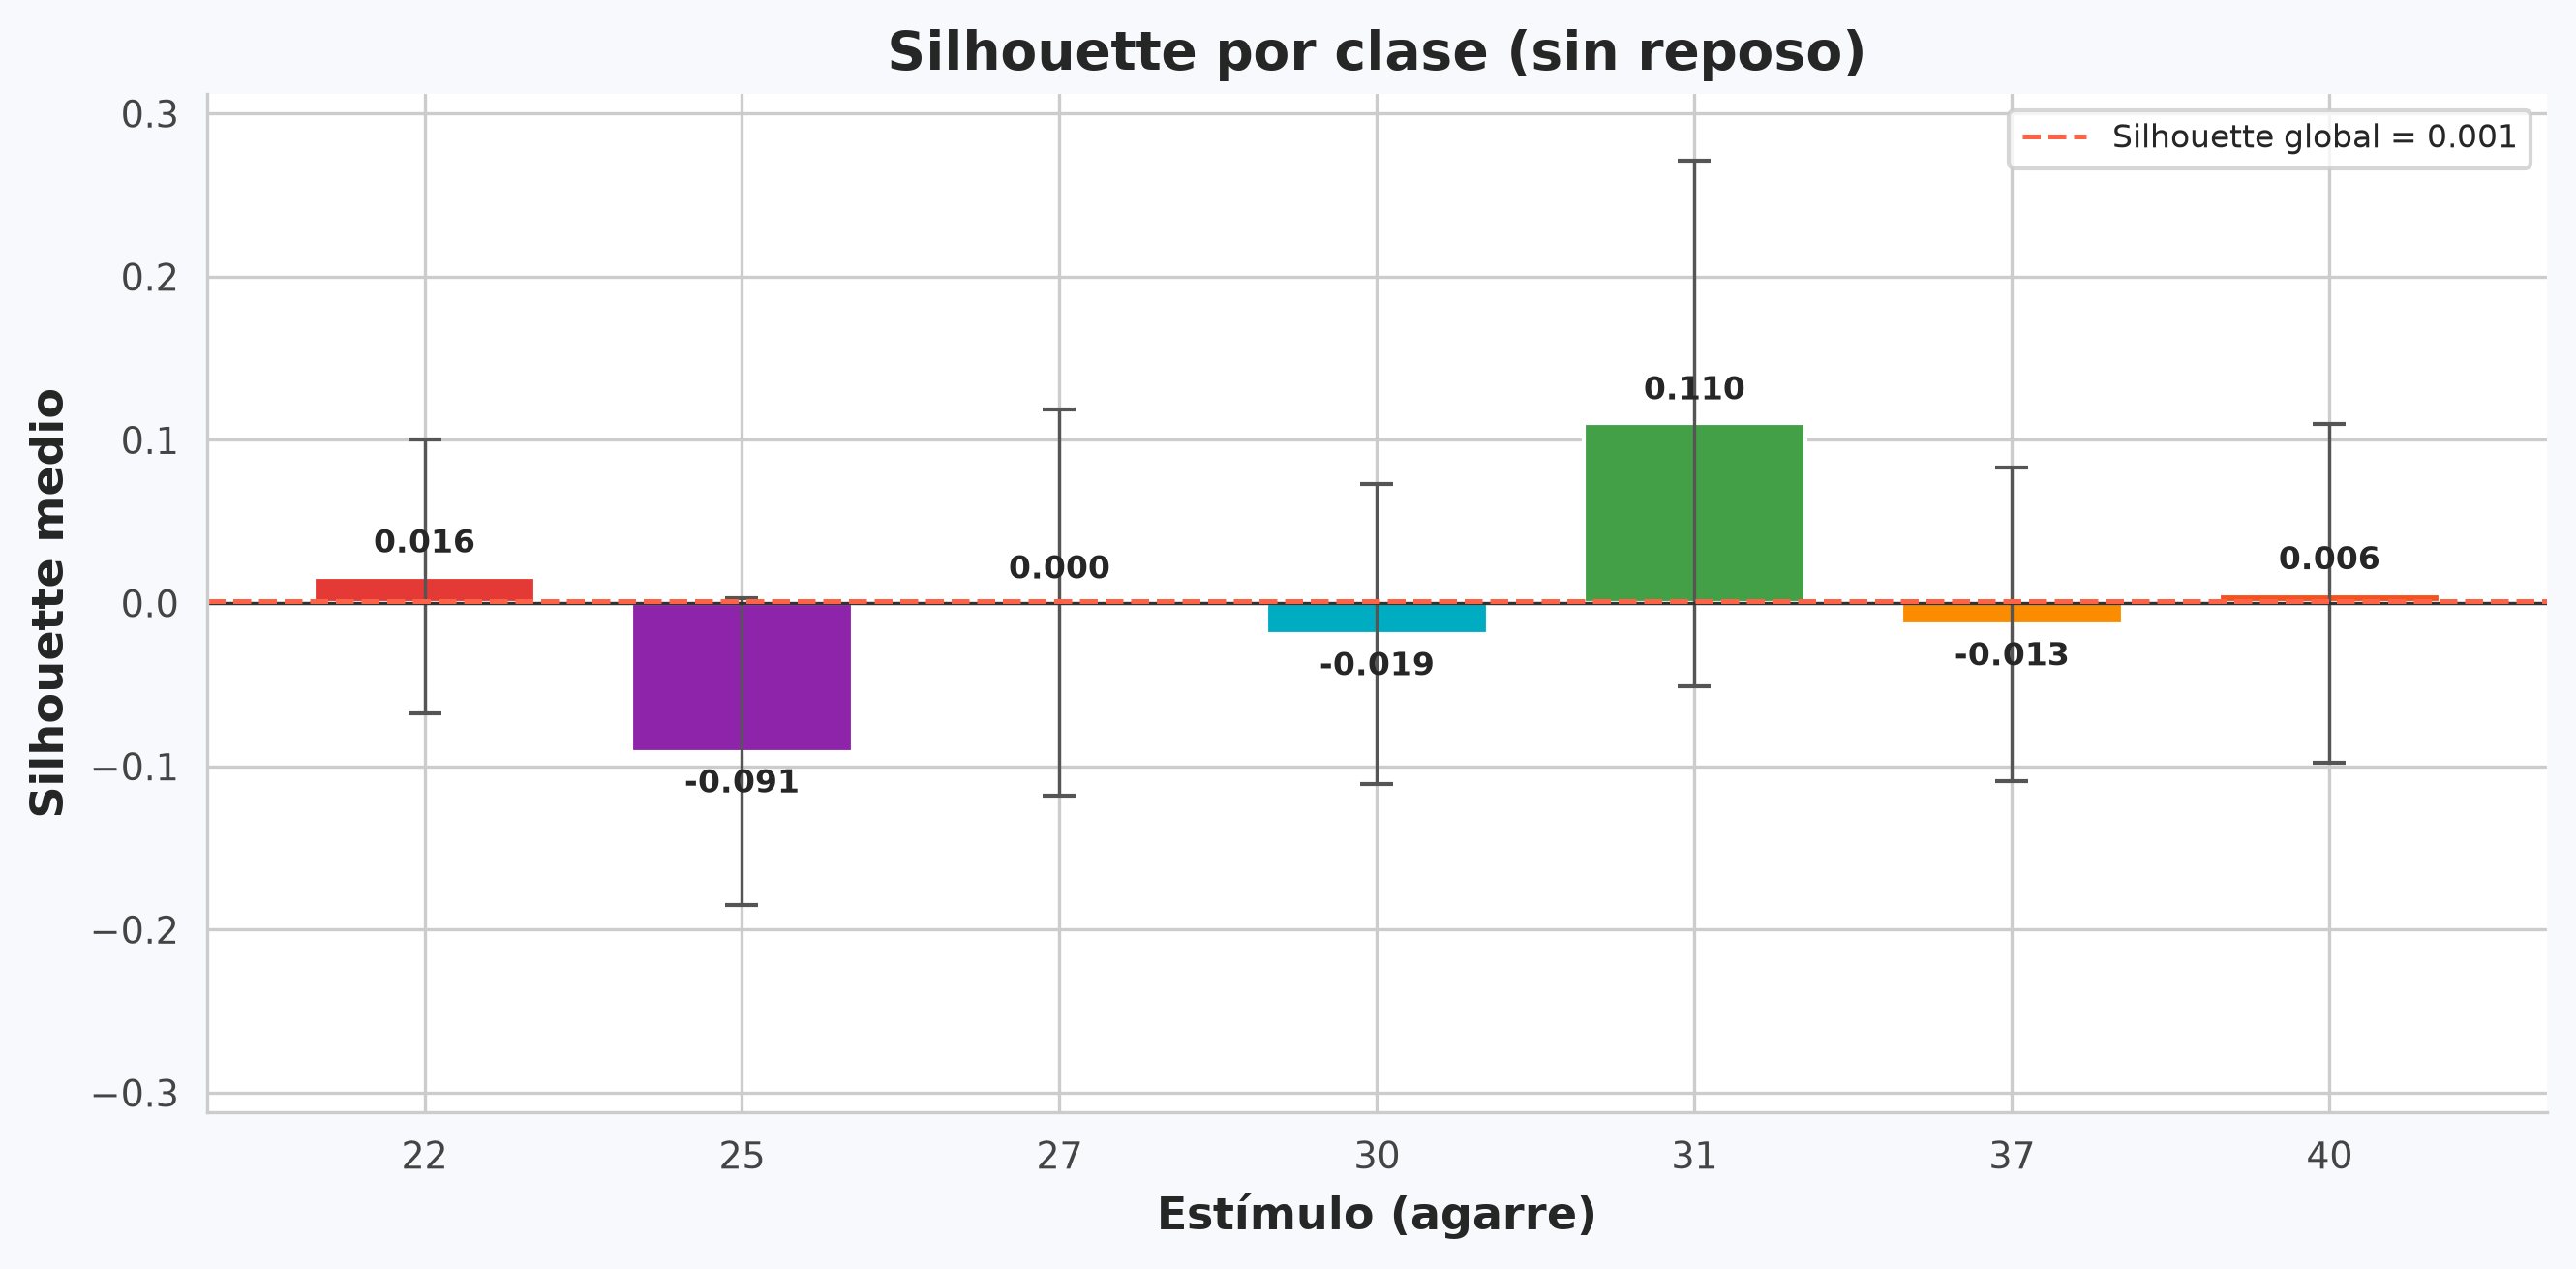

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=300)
fig.patch.set_facecolor('#F7F9FC')
ax.set_facecolor('#FFFFFF')

vals = sil_class.loc[STIMULI, 'media']
errs = sil_class.loc[STIMULI, 'desv']
bars = ax.bar([str(s) for s in STIMULI], vals,
              color=[stim_color_map[s] for s in STIMULI], edgecolor='white', width=0.7,
              yerr=errs, capsize=4, error_kw=dict(ecolor='#555555', lw=0.8))
ax.axhline(0, color='#333333', linewidth=0.8)
ax.axhline(sil_global, color='tomato', linestyle='--', linewidth=1.2,
           label=f'Silhouette global = {sil_global:.3f}')

# Etiquetas por encima (positivos) o por debajo (negativos) de cada barra
offset = 0.01
for bar, val in zip(bars, vals):
    va = 'bottom' if val >= 0 else 'top'
    ax.text(bar.get_x() + bar.get_width() / 2, val + (offset if val >= 0 else -offset),
            f'{val:.3f}', ha='center', va=va, fontsize=8, fontweight='bold')

# Límites simétricos que incluyen valores negativos y barras de error
lim = max(np.abs(vals - errs).max(), np.abs(vals + errs).max()) * 1.15
ax.set_ylim(-lim, lim)

ax.set_xlabel('Estímulo (agarre)', fontweight='bold')
ax.set_ylabel('Silhouette medio', fontweight='bold')
ax.set_title('Silhouette por clase (sin reposo)', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#CCCCCC')
ax.tick_params(colors='#444444', labelsize=9)
ax.legend(frameon=True, fontsize=8)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/silhouette_per_class.pdf', dpi=300, bbox_inches='tight')
plt.show()

## 6. Proyección LDA (descriptiva)

LDA ajustada con **todos** los sujetos, solo para visualizar. Como usa todas las etiquetas, la separación
que se ve aquí es optimista: las cifras de separabilidad válidas son las de LOSO (secciones 3 y 4).
Máximo **min(n_clases − 1, n_variables)** componentes discriminantes.

,Componente,Poder discriminante (λ),Proporción,Acumulada
0,LD1,3.9537,0.5109,0.5109
1,LD2,1.5512,0.2005,0.7114
2,LD3,0.9375,0.1211,0.8325
3,LD4,0.6005,0.0776,0.9101
4,LD5,0.4533,0.0586,0.9687
5,LD6,0.2423,0.0313,1.0000


LD1 + LD2 concentran el 71.14% del poder discriminante


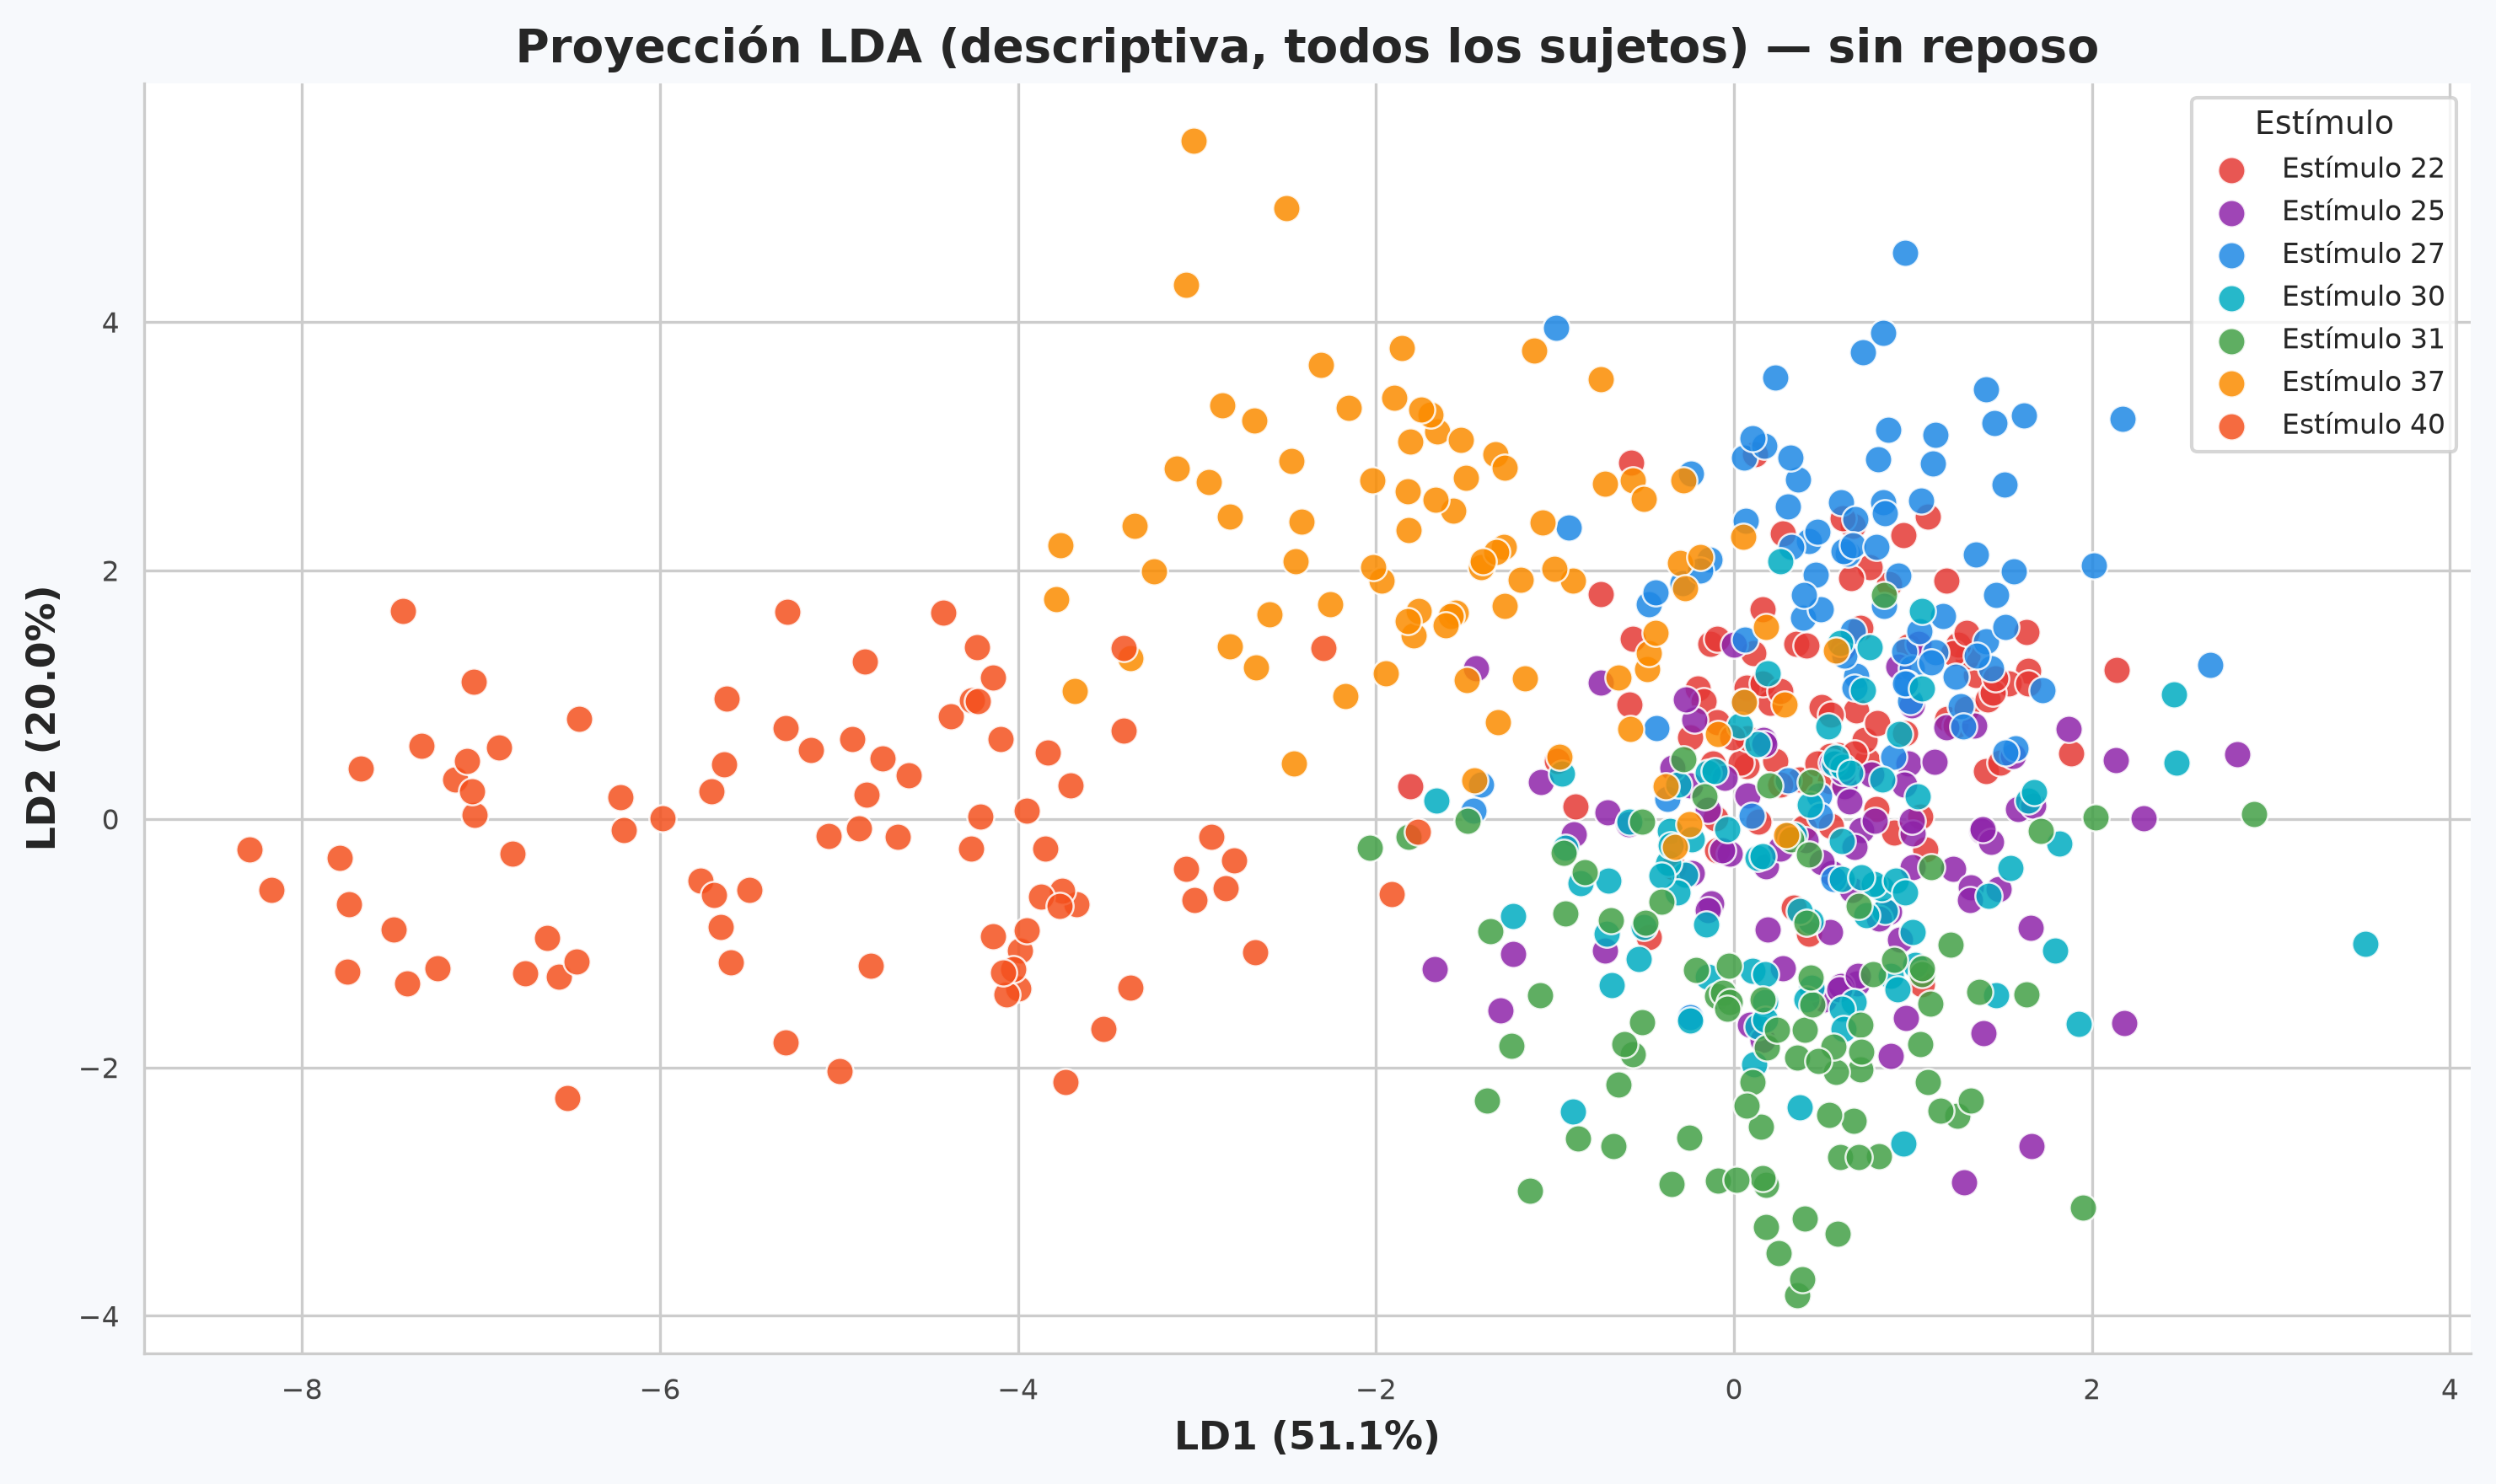

In [13]:
lda_vis = make_lda(for_transform=True)
X_lda = lda_vis.fit_transform(X, y)

def fisher_axis(z, y):
    """Razón entre-clases / intra-clases de una proyección 1D (siempre >= 0)."""
    mu = z.mean()
    sb = sw = 0.0
    for c in np.unique(y):
        zc = z[y == c]
        sb += len(zc) * (zc.mean() - mu) ** 2
        sw += ((zc - zc.mean()) ** 2).sum()
    return sb / sw

pod = np.array([fisher_axis(X_lda[:, k], y) for k in range(X_lda.shape[1])])
evr = pod / pod.sum()          # suma 1, todo en [0, 1]

var_df = pd.DataFrame({
    'Componente': [f'LD{i+1}' for i in range(len(evr))],
    'Poder discriminante (λ)': pod,
    'Proporción': evr,
    'Acumulada': np.cumsum(evr),
})
display(var_df.style.format({'Poder discriminante (λ)': '{:.4f}',
                             'Proporción': '{:.4f}', 'Acumulada': '{:.4f}'}))
print(f'LD1 + LD2 concentran el {evr[:2].sum()*100:.2f}% del poder discriminante')

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
fig.patch.set_facecolor('#F7F9FC')
ax.set_facecolor('#FFFFFF')

for stim, color in zip(STIMULI, STIM_COLORS):
    mask = y == stim
    ax.scatter(X_lda[mask, 0], X_lda[mask, 1], s=60, alpha=0.85,
               edgecolor='white', linewidth=0.6, color=color, label=f'Estímulo {stim}')

ax.set_xlabel(f'LD1 ({evr[0]*100:.1f}%)', fontweight='bold')
ax.set_ylabel(f'LD2 ({evr[1]*100:.1f}%)', fontweight='bold')
ax.set_title('Proyección LDA (descriptiva, todos los sujetos) — sin reposo', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#CCCCCC')
ax.tick_params(colors='#444444', labelsize=8)
ax.legend(title='Estímulo', frameon=True, loc='best', fontsize=8, title_fontsize=9)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/lda_projection.pdf', dpi=300, bbox_inches='tight')
plt.show()

## 7. Resumen automático

Se genera a partir de los resultados, para que no quede desactualizado si cambias `SHRINKAGE`.

In [14]:
fdr_var = fdr_df.set_index('Variable')['FDR']
sil_sorted = sil_class['media'].sort_values(ascending=False)

print(f'Configuración: {N_FEATURES} variables, SHRINKAGE={SHRINKAGE!r}, '
      f'{len(np.unique(groups))} sujetos, {len(STIMULI)} agarres\n')
print('Fisher Discriminant Ratio')
print(f'  FDR global = {fdr_global_value:.3f}')
print(f'  Variables más discriminativas: {", ".join(f"{v} ({x:.3f})" for v, x in fdr_var.head(3).items())}')
print(f'  Variables menos discriminativas: {", ".join(f"{v} ({x:.3f})" for v, x in fdr_var.tail(2).items())}\n')
print('LDA multiclase LOSO')
print(f'  Accuracy por sujeto = {per_group_df["accuracy"].mean():.3f} ± {per_group_df["accuracy"].std():.3f} '
      f'(azar = {CHANCE:.3f}); balanced accuracy = {bacc_global:.3f}')
print(f'  Mejor reconocido: {recall_df["Recall"].idxmax()} ({recall_df["Recall"].max():.3f}) | '
      f'peor: {recall_df["Recall"].idxmin()} ({recall_df["Recall"].min():.3f})')
print(f'  Pares más confundidos: ' + ', '.join(
    f'{r.agarre_a}–{r.agarre_b} ({r.confusion:.3f})' for r in conf_pairs_df.head(3).itertuples()) + '\n')
print('Solapamiento por pares (LDA binaria LOSO)')
print(f'  Error medio = {overlap[np.triu_indices(n, 1)].mean():.3f}')
print(f'  Más solapados: ' + ', '.join(
    f'{r.agarre_a}–{r.agarre_b} ({r.error:.3f})' for r in pairs_df.head(3).itertuples()))
print(f'  Menos solapados: ' + ', '.join(
    f'{r.agarre_a}–{r.agarre_b} ({r.error:.3f})' for r in pairs_df.tail(3).itertuples()) + '\n')
print('Silhouette')
print(f'  Global = {sil_global:.3f}; mejor clase {sil_sorted.index[0]} ({sil_sorted.iloc[0]:.3f}), '
      f'peor {sil_sorted.index[-1]} ({sil_sorted.iloc[-1]:.3f})')

Configuración: 200 variables, SHRINKAGE='auto', 87 sujetos, 7 agarres

Fisher Discriminant Ratio
  FDR global = 0.381
  Variables más discriminativas: Max_w22 (1.201), Max_w21 (1.187), Energy_w21 (1.179)
  Variables menos discriminativas: SSC_w4 (0.004), SSC_w0 (0.001)

LDA multiclase LOSO
  Accuracy por sujeto = 0.724 ± 0.179 (azar = 0.143); balanced accuracy = 0.724
  Mejor reconocido: 40 (0.931) | peor: 22 (0.644)
  Pares más confundidos: 22–27 (0.126), 22–30 (0.121), 25–31 (0.115)

Solapamiento por pares (LDA binaria LOSO)
  Error medio = 0.090
  Más solapados: 30–31 (0.178), 22–27 (0.167), 22–30 (0.155)
  Menos solapados: 31–40 (0.029), 27–40 (0.023), 30–40 (0.023)

Silhouette
  Global = 0.001; mejor clase 31 (0.110), peor 25 (-0.091)
